## 3-Ecommerce

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [69]:
# --- Adım 1: Veri Seti Oluşturma ---
data = {
    'Sitede_Gecirilen_Dakika': [
        5, 8, 10, 12, 15, 18, 20, 22, 25, 28, 
        30, 35, 40, 45, 50, 55, 60, 65, 70, 75
    ],
    'Sepetteki_Urun_Sayisi': [
        1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 
        4, 4, 4, 5, 5, 6, 6, 7, 7, 8
    ],
    'Toplam_Harcama_TL': [
        250, 320, 400, 480, 650, 720, 800, 950, 1100, 1220, 
        1400, 1580, 1750, 2100, 2300, 2550, 2800, 3100, 3350, 3500
    ]
}

In [70]:
df = pd.DataFrame(data)

In [78]:
df

,Sitede_Gecirilen_Dakika,Sepetteki_Urun_Sayisi,Toplam_Harcama_TL
0,5,1,250
1,8,1,320
2,10,1,400
3,12,2,480
4,15,2,650
5,18,2,720
6,20,2,800
7,22,3,950
8,25,3,1100
9,28,3,1220


In [79]:
df.isna().sum()

Sitede_Gecirilen_Dakika    0
Sepetteki_Urun_Sayisi      0
Toplam_Harcama_TL          0
dtype: int64

In [80]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Sitede_Gecirilen_Dakika,20.0,34.4,21.924272,5.0,17.25,29.0,51.25,75.0
Sepetteki_Urun_Sayisi,20.0,3.8,2.166734,1.0,2.00,3.5,5.25,8.0
Toplam_Harcama_TL,20.0,1566.0,1059.639462,250.0,702.50,1310.0,2362.50,3500.0


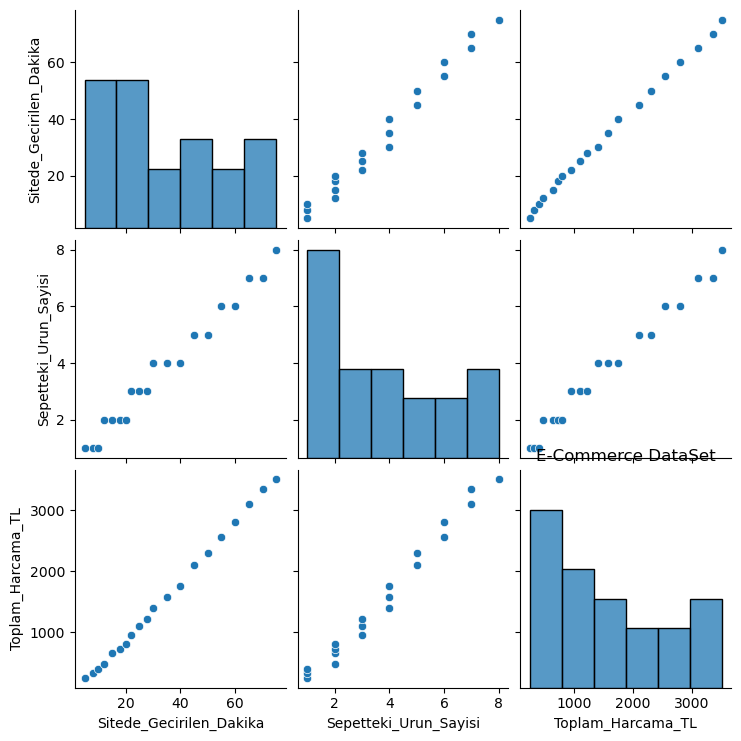

In [81]:
sns.pairplot(df)
plt.title("E-Commerce DataSet")
plt.show()

In [82]:
df.columns

Index(['Sitede_Gecirilen_Dakika', 'Sepetteki_Urun_Sayisi',
       'Toplam_Harcama_TL'],
      dtype='object')

In [85]:
X = df[['Sitede_Gecirilen_Dakika', 'Sepetteki_Urun_Sayisi']]
y = df['Toplam_Harcama_TL']

In [86]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [87]:
# --- Adım 5: Ölçeklendirme (Data Leakage Önleme) ---
scaler = StandardScaler()

In [88]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [89]:
# --- Adım 6: Model Eğitimi (fit) ---
model = LinearRegression()
model.fit(X_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [90]:
for col,coef in zip(X.columns,model.coef_):
    print(f"{col} Etki Katsayisi: {coef:.2f}")

Sitede_Gecirilen_Dakika Etki Katsayisi: 868.12
Sepetteki_Urun_Sayisi Etki Katsayisi: 91.82


In [91]:
# --- Adım 7: Tahmin ve Performans Metrikleri ---
y_pred = model.predict(X_test_scaled)

In [92]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2_degeri = r2_score(y_test, y_pred)

print(f"\n[MODEL PERFORMANSI]")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2_degeri:.2f}")


[MODEL PERFORMANSI]
MAE: 62.08
RMSE: 73.44
R2 Score: 1.00


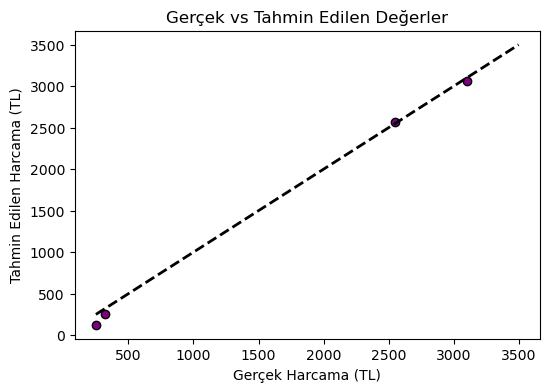

In [93]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred, color='purple', edgecolors='k')
plt.xlabel("Gerçek Harcama (TL)")
plt.ylabel("Tahmin Edilen Harcama (TL)")
plt.title("Gerçek vs Tahmin Edilen Değerler")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2) # İdeal 45 derece çizgisi
plt.show()